# Etapa 2: modelagem e inteligência de negócio

Esta etapa treina três modelos para prever o nível de risco de incêndio (Baixo, Médio ou Alto) de cada
município-dia, compara os três com a régua da Etapa 1, transforma o resultado em reais e planeja um teste A/B
(experimento que sorteia grupos, um com o modelo e outro sem) para comprovar o ganho na prática.

**Hipótese do projeto:** com o que se sabe até a véspera, um modelo avisa os dias de risco Alto melhor do que a
régua mínima e reduz o custo de posicionar equipes. A resposta está no fim da Etapa 3.

**Lembrete da Etapa 1** (`01_eda.ipynb`):
- **Alvo** (o que o modelo prevê): o nível de risco do dia. Baixo = nenhum foco; Médio = 1 a 3 focos;
  Alto = 4 ou mais focos de satélites de órbita polar.
- **Features** (as colunas que o modelo usa): só o que se sabe até a véspera. Histórico de focos, clima da
  véspera, calendário, uso do solo e estado.
- **Régua mínima:** a persistência, que prevê que o risco de hoje é o mesmo de ontem.
- **Metas:** avisar pelo menos 60 de cada 100 dias Alto, com pelo menos 55 de cada 100 avisos certos, e
  acerto geral de pelo menos 0,55.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'consolidar_base.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
import preparar_modelagem as pm

RELATORIOS = RAIZ / 'resultados' / 'etapa2'
RELATORIOS.mkdir(parents=True, exist_ok=True)
AZUL, CINZA, VERMELHO = '#2f6fdb', '#9aa5b1', '#c0392b'
SEMENTE = 12345
print(f'Ambiente pronto: pandas {pd.__version__}, LightGBM {lgb.__version__}')

Ambiente pronto: pandas 3.1.0, LightGBM 4.7.0


## 1. A divisão por tempo

O modelo vai ser usado para prever o futuro, então ele é avaliado no futuro. A base é dividida em três
períodos seguidos:

| Parte | Período | Para que serve |
|---|---|---|
| **Treino** | 31/01 a 30/09/2024 | o modelo aprende os padrões; inclui o pico da seca (agosto e setembro) |
| **Validação** | outubro de 2024 | escolher as notas de corte (seção 4), como um simulado |
| **Teste** | 01/11/2024 a 12/02/2025 | a nota final; os modelos e as notas de corte não são escolhidos olhando para ele |

Sortear as linhas misturaria o futuro no treino: o modelo veria, por exemplo, o fogo de 15 de setembro ao
aprender o de 14 de setembro.

In [2]:
base = pm.carregar_base()
treino, validacao, teste = pm.dividir_por_tempo(base)

partes = pd.DataFrame({
    nome: {'primeiro dia': d['dia'].min().date(), 'último dia': d['dia'].max().date(), 'linhas': len(d),
           **(d['nivel_risco'].value_counts(normalize=True) * 100).round(2).to_dict()}
    for nome, d in [('treino', treino), ('validação', validacao), ('teste', teste)]}).T
partes

,primeiro dia,último dia,linhas,Baixo,Médio,Alto
treino,2024-01-31,2024-09-30,1355812,86.69,7.37,5.94
validação,2024-10-01,2024-10-31,172316,76.89,10.7,12.41
teste,2024-11-01,2025-02-12,578283,86.46,8.25,5.29


**As três partes não têm a mesma mistura de níveis.** A validação (outubro) ainda é seca, com 12,41% de dias
Alto; o teste (novembro a fevereiro) entra na época de chuva, com 5,29%. Isso é proposital, e é o mais
honesto: no uso real, o modelo vai enfrentar meses que ainda não viu. A seção 6.1 mostra a nota mês a mês.

**Um limite que vem da base:** o treino não tem nenhum dia de outubro, novembro ou dezembro, porque os dados só
cobrem um ano. Para as colunas de calendário, esses meses são novos, e os modelos de árvores os tratam como o último
mês conhecido (setembro, o pico da seca).

## 2. As réguas

Antes dos modelos, duas réguas, medidas na validação e no teste:
- **"Sempre Baixo":** prever que nunca haverá risco. Mostra por que a acurácia engana.
- **Persistência:** prever que o risco de hoje é o de ontem. É a régua mínima que o modelo precisa superar.

**As métricas usadas daqui em diante, em português:**
- **Acurácia:** a fração de dias acertados. Engana quando um nível é raro: quem chuta sempre o nível comum
  acerta muito e não serve para nada.
- **Precisão do Alto (avisos certos):** dos dias que o método chamou de Alto, quantos foram Alto.
- **Recall do Alto (dias Alto avisados):** dos dias que foram Alto, quantos o método avisou.
- **F1:** junta precisão e recall numa nota de 0 a 1, que só fica alta se as duas forem altas. O **F1 do Alto**
  olha só o nível Alto; o **F1 macro (acerto geral)** é a média dos F1 de Baixo, Médio e Alto, com o mesmo peso
  para os três.
- **AUC-ROC:** de 0,5 (sorteio) a 1 (perfeito), o quanto o método ordena bem os dias, do mais arriscado para
  o menos, antes de qualquer nota de corte (seção 4). Só existe para os modelos, que dão probabilidades.

In [3]:
y_va, y_te = validacao['nivel_risco'].astype(str), teste['nivel_risco'].astype(str)
reguas = pd.DataFrame({
    'sempre Baixo (teste)': pm.metricas(y_te, np.full(len(y_te), 'Baixo')),
    'persistência (validação)': pm.metricas(y_va, pm.persistencia(validacao)),
    'persistência (teste)': pm.metricas(y_te, pm.persistencia(teste)),
}).T.round(4)
reguas

,acuracia,f1_macro,precisao_alto,recall_alto,f1_alto,f1_medio
sempre Baixo (teste),0.8646,0.3091,0.0000,0.0000,0.0000,0.0000
persistência (validação),0.7776,0.5697,0.6004,0.6044,0.6024,0.2236
persistência (teste),0.8423,0.5490,0.4921,0.4982,0.4951,0.2295


"Sempre Baixo" acerta **86,46%** dos dias do teste e nunca avisa um incêndio: é por isso que a acurácia não é a
métrica principal. No teste, a persistência avisa 50 de cada 100 dias Alto, com 49 de cada 100
avisos certos, e tem acerto geral (F1 macro) de 0,5490.

## 3. Os três modelos

| Modelo | Como funciona | Cuidados de preparação |
|---|---|---|
| **Regressão logística** | dá um peso a cada coluna, soma tudo e transforma a soma numa probabilidade para cada nível | preenche vazios com a mediana do treino (o valor do meio) e avisa que estava vazio; aplica log (que encolhe os valores enormes) nas colunas de cauda longa, que têm muitos valores pequenos e poucos enormes, como chuva e focos; põe os números na mesma escala; transforma o estado em colunas de 0 e 1 |
| **Floresta aleatória** | centenas de árvores de decisão (sequências de perguntas como "a umidade de ontem ficou abaixo de 30%?"), cada uma treinada com uma amostra diferente, que votam no fim | preenche vazios com a mediana do treino e avisa que estava vazio |
| **LightGBM** | árvores em sequência, cada uma corrigindo os erros das anteriores | nenhum: lida sozinho com vazios e com o estado |

Os três usam **peso maior para os níveis raros** (`class_weight='balanced'`), para não ignorar Médio e Alto,
que juntos são cerca de 13% do treino. Os vazios são preenchidos **só com valores do treino**, dentro de um
`Pipeline` (uma linha de montagem que aprende os ajustes no treino e os aplica igual na validação e no
teste), para nada do futuro vazar para o treino.

**Clima quase completo.** A Etapa 1 tirou as linhas sem nenhuma medida de clima. Os poucos vazios restantes, menos de
0,2% em cada coluna, são preenchidos como descrito acima.

**Amostra de treino.** Os modelos aprendem com uma amostra aleatória de 400 mil das 1,36 milhão de linhas do
treino. Com isso, os três treinam em segundos, e a amostra mantém a mesma mistura de níveis. A validação e o
teste são usados inteiros.

In [4]:
amostra = treino.sample(400_000, random_state=SEMENTE)
X_am, y_am = amostra[pm.FEATURES], amostra['nivel_risco'].astype(str)
X_va, X_te = validacao[pm.FEATURES], teste[pm.FEATURES]

outras = [c for c in pm.FEATURES_NUMERICAS if c not in pm.FEATURES_CAUDA_LONGA]
preparo_logistica = ColumnTransformer([
    ('cauda_longa', Pipeline([('vazios', SimpleImputer(strategy='median', add_indicator=True)),
                              ('log', FunctionTransformer(np.log1p)), ('escala', StandardScaler())]), pm.FEATURES_CAUDA_LONGA),
    ('numericas', Pipeline([('vazios', SimpleImputer(strategy='median', add_indicator=True)),
                            ('escala', StandardScaler())]), outras),
    ('estado', OneHotEncoder(handle_unknown='ignore'), pm.FEATURES_CATEGORICAS)])
preparo_floresta = ColumnTransformer([
    ('numericas', SimpleImputer(strategy='median', add_indicator=True), pm.FEATURES_NUMERICAS),
    ('estado', OneHotEncoder(handle_unknown='ignore'), pm.FEATURES_CATEGORICAS)])

modelos = {
    'Regressão logística': Pipeline([('preparo', preparo_logistica),
                                     ('modelo', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
    'Floresta aleatória': Pipeline([('preparo', preparo_floresta),
                                    ('modelo', RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=50,
                                                                      class_weight='balanced', n_jobs=-1, random_state=SEMENTE))]),
    'LightGBM': lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, class_weight='balanced',
                                   random_state=SEMENTE, verbose=-1),
}

def probabilidades(modelo, X):
    ordem = [list(modelo.classes_).index(n) for n in pm.NIVEIS]
    return modelo.predict_proba(X)[:, ordem]

prob_va, prob_te = {}, {}
for nome, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_am, y_am)
    prob_va[nome], prob_te[nome] = probabilidades(modelo, X_va), probabilidades(modelo, X_te)
    print(f'{nome:<20} treinado em {time.time() - inicio:.0f} s')

Regressão logística  treinado em 4 s


Floresta aleatória   treinado em 9 s


LightGBM             treinado em 12 s


## 4. As notas de corte, escolhidas na validação

Cada modelo devolve três probabilidades por município-dia (Baixo, Médio e Alto). Para virar um aviso, é preciso
uma **nota de corte**: a partir de que probabilidade o dia vira Alto? A regra usada é:

1. se a probabilidade de Alto passa do corte do Alto, o dia é **Alto**;
2. senão, se a de Médio passa do corte do Médio, é **Médio**;
3. senão, é **Baixo**.

Os dois cortes são escolhidos **só na validação** (outubro), procurando o par que dá o maior acerto geral
(F1 macro). O teste fica guardado: escolher o corte olhando o teste seria colar na prova. A última coluna da tabela
mostra outra medida, usada na seção 5: o melhor F1 do Alto que cada modelo alcança na validação.

In [5]:
cortes = {}
for nome in modelos:
    corte_alto, corte_medio, f1_validacao = pm.escolher_cortes(y_va, prob_va[nome])
    melhor_f1_alto = max(f1_score(y_va == 'Alto', prob_va[nome][:, 2] >= corte) for corte in np.round(np.arange(0.10, 0.91, 0.05), 2))
    cortes[nome] = {'corte_alto': corte_alto, 'corte_medio': corte_medio, 'f1_macro_validacao': round(f1_validacao, 4),
                    'melhor_f1_alto_validacao': round(melhor_f1_alto, 4)}
pd.DataFrame(cortes).T.to_csv(RELATORIOS / 'cortes_validacao.csv')
pd.DataFrame(cortes).T

,corte_alto,corte_medio,f1_macro_validacao,melhor_f1_alto_validacao
Regressão logística,0.60,0.50,0.5794,0.6387
Floresta aleatória,0.55,0.50,0.5790,0.6407
LightGBM,0.45,0.55,0.5762,0.6073


## 5. A comparação no teste

Agora os modelos são medidos no teste, com os cortes já fixados na validação.
As métricas são as da seção 2.

In [6]:
resultados = {'Persistência': pm.metricas(y_te, pm.persistencia(teste))}
previsoes = {}
for nome in modelos:
    previsoes[nome] = pm.decidir(prob_te[nome], cortes[nome]['corte_alto'], cortes[nome]['corte_medio'])
    resultados[nome] = pm.metricas(y_te, previsoes[nome], prob_te[nome])
tabela = pd.DataFrame(resultados).T[['acuracia', 'f1_macro', 'precisao_alto', 'recall_alto', 'f1_alto', 'f1_medio', 'auc_roc']].round(4)
tabela.to_csv(RELATORIOS / 'metricas_teste.csv')
tabela

,acuracia,f1_macro,precisao_alto,recall_alto,f1_alto,f1_medio,auc_roc
Persistência,0.8423,0.5490,0.4921,0.4982,0.4951,0.2295,NaN
Regressão logística,0.8174,0.5649,0.5870,0.4988,0.5393,0.2519,0.8550
Floresta aleatória,0.7962,0.5644,0.5729,0.5273,0.5492,0.2543,0.8559
LightGBM,0.8196,0.5603,0.5323,0.4778,0.5036,0.2702,0.8526


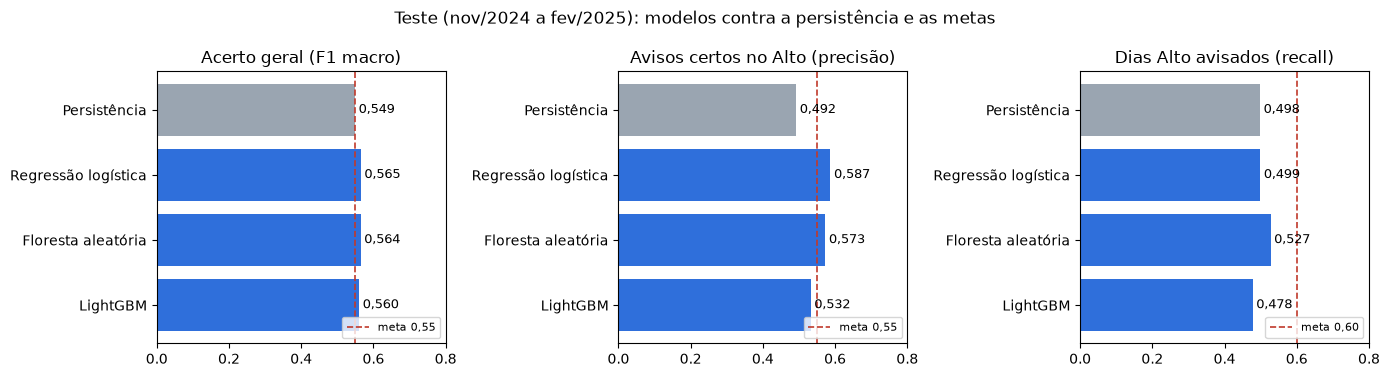

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
for eixo, coluna, titulo, meta in zip(eixos, ['f1_macro', 'precisao_alto', 'recall_alto'],
                                      ['Acerto geral (F1 macro)', 'Avisos certos no Alto (precisão)', 'Dias Alto avisados (recall)'],
                                      [0.55, 0.55, 0.60]):
    valores = tabela[coluna]
    eixo.barh(valores.index, valores.values, color=[CINZA, AZUL, AZUL, AZUL])
    for posicao, valor in enumerate(valores.values):
        eixo.text(valor + 0.01, posicao, f'{valor:.3f}'.replace('.', ','), va='center', fontsize=9)
    linha_meta = eixo.axvline(meta, color=VERMELHO, linestyle='--', linewidth=1.2)
    eixo.set_title(titulo)
    eixo.set_xlim(0, 0.8)
    eixo.invert_yaxis()
    eixo.legend([linha_meta], [f'meta {meta:.2f}'.replace('.', ',')], loc='lower right', fontsize=8)
plt.suptitle('Teste (nov/2024 a fev/2025): modelos contra a persistência e as metas')
plt.tight_layout()
plt.show()

**Os três modelos superam a persistência no acerto geral e no F1 do Alto.** A regressão logística tem o maior acerto
geral no teste (0,5649, contra 0,5490 da persistência), com 58,7 de cada 100 avisos Alto certos (persistência: 49,2) e
49,9 de cada 100 dias Alto avisados (persistência: 49,8). Um detalhe: o LightGBM sem ajustes é o único
que avisa menos dias Alto que a persistência (47,8).

A **regressão logística** segue como modelo escolhido por ter o maior acerto geral na validação (0,5794), que foi o
critério decidido antes de olhar o teste. A diferença entre os três é pequena.

**As metas, uma a uma, para a regressão logística:**

| Meta | Regressão logística | Atingida? |
|---|---|---|
| acerto geral (F1 macro) de pelo menos 0,55 | 0,5649 | **sim** |
| pelo menos 55 de cada 100 avisos Alto certos | 58,7 | **sim** |
| pelo menos 60 de cada 100 dias Alto avisados | 49,9 | **não**, e nenhum dos três modelos chega lá |

O recall fica abaixo da meta porque os cortes foram escolhidos para o maior acerto geral, e não para avisar mais. A
seção 7.2 mostra que, pelo custo em reais, vale avisar mais dias. A Etapa 3 (otimização com Optuna, uma ferramenta que
testa combinações de ajustes do modelo) tenta melhorar esse ponto.

**Um ponto de atenção:** as metas principais são sobre o Alto, e o critério de escolha é o acerto geral, porque o modelo
precisa separar os três níveis. Olhando só o F1 do Alto na validação, a floresta (0,6407) fica logo à frente da regressão
logística (0,6387), e o LightGBM sem ajustes fica atrás (0,6073). A escolha não muda, mas a diferença fica registrada.

Modelo escolhido pela validação: Regressão logística


            previsto Baixo  previsto Médio  previsto Alto
real Baixo          442108           52459           5413
real Médio           27101           15301           5318
real Alto             9317            6012          15254


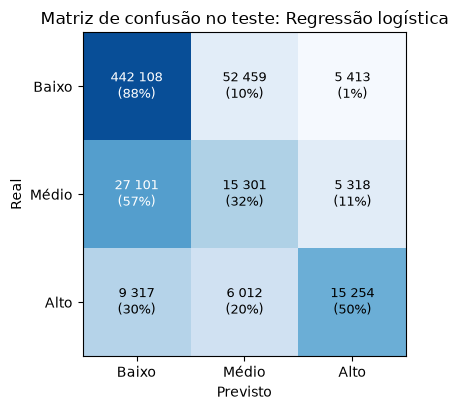

In [8]:
escolhido = max(cortes, key=lambda nome: cortes[nome]['f1_macro_validacao'])
print('Modelo escolhido pela validação:', escolhido)
matriz = pd.DataFrame(confusion_matrix(y_te, previsoes[escolhido], labels=pm.NIVEIS),
                      index=[f'real {n}' for n in pm.NIVEIS], columns=[f'previsto {n}' for n in pm.NIVEIS])
matriz.to_csv(RELATORIOS / 'matriz_confusao_teste.csv')
print(matriz)

fig, eixo = plt.subplots(figsize=(5.5, 4.2))
proporcao = matriz.div(matriz.sum(axis=1), axis=0)
eixo.imshow(proporcao, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        eixo.text(j, i, f'{matriz.iloc[i, j]:,}'.replace(',', ' ') + f'\n({proporcao.iloc[i, j]:.0%})', ha='center', va='center',
                  color='white' if proporcao.iloc[i, j] > 0.5 else 'black', fontsize=9)
eixo.set_xticks(range(3)); eixo.set_xticklabels(pm.NIVEIS)
eixo.set_yticks(range(3)); eixo.set_yticklabels(pm.NIVEIS)
eixo.set_xlabel('Previsto'); eixo.set_ylabel('Real')
eixo.set_title(f'Matriz de confusão no teste: {escolhido}')
plt.tight_layout()
plt.show()

**Como ler a matriz de confusão:** cada linha é o que aconteceu, cada coluna é o que o modelo disse, e a
diagonal são os acertos. Dos dias que foram Alto (última linha), o modelo chamou 50% de Alto, 20% de
Médio e 30% de Baixo. O erro mais caro é o Alto chamado de Baixo (incêndio sem aviso nenhum). O Médio é o nível
mais confundido, como a Etapa 1 já mostrava: o fogo isolado é o mais difícil de prever.

## 6. Robustez: o resultado se sustenta?

### 6.1. Mês a mês

             parte  % dias Alto  F1 macro modelo  F1 macro persistência  \
mês                                                                       
2024-10  validação        12.41           0.5794                 0.5697   
2024-11      teste         8.85           0.5810                 0.5689   
2024-12      teste         6.47           0.5581                 0.5502   
2025-01      teste         2.14           0.4861                 0.4826   
2025-02      teste         1.46           0.4508                 0.4575   

         F1 Alto modelo  F1 Alto persistência  
mês                                            
2024-10          0.6387                0.6024  
2024-11          0.6075                0.5639  
2024-12          0.5261                0.4900  
2025-01          0.2837                0.3035  
2025-02          0.1835                0.2499  


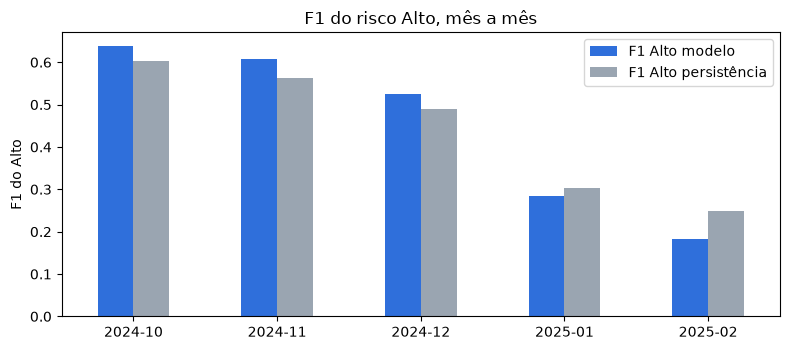

In [9]:
mes_a_mes = []
for nome_parte, parte, prob in [('validação', validacao, prob_va[escolhido]), ('teste', teste, prob_te[escolhido])]:
    prev = pm.decidir(prob, cortes[escolhido]['corte_alto'], cortes[escolhido]['corte_medio'])
    for mes, indices in parte.groupby(parte['dia'].dt.to_period('M')).indices.items():
        y_mes = parte['nivel_risco'].astype(str).iloc[indices]
        modelo_mes = pm.metricas(y_mes, prev[indices])
        regua_mes = pm.metricas(y_mes, pm.persistencia(parte.iloc[indices]))
        mes_a_mes.append({'mês': str(mes), 'parte': nome_parte, '% dias Alto': round((y_mes == 'Alto').mean() * 100, 2),
                          'F1 macro modelo': modelo_mes['f1_macro'], 'F1 macro persistência': regua_mes['f1_macro'],
                          'F1 Alto modelo': modelo_mes['f1_alto'], 'F1 Alto persistência': regua_mes['f1_alto']})
mes_a_mes = pd.DataFrame(mes_a_mes).set_index('mês').round(4)
mes_a_mes.to_csv(RELATORIOS / 'mes_a_mes.csv')
print(mes_a_mes)

mes_a_mes[['F1 Alto modelo', 'F1 Alto persistência']].plot(kind='bar', rot=0, color=[AZUL, CINZA], figsize=(8, 3.6))
plt.title('F1 do risco Alto, mês a mês')
plt.ylabel('F1 do Alto')
plt.xlabel('')
plt.tight_layout()
plt.show()

O modelo fica acima da persistência no risco Alto em **3 de 5 meses**: outubro, novembro e dezembro, os meses com mais
fogo. Em janeiro e fevereiro, com a chuva e poucos dias Alto, ele fica abaixo (F1 do Alto de 0,2837 e 0,1835, contra
0,3035 e 0,2499). Os dois caem nesses meses, mas o modelo cai mais: esse é um limite real do corte único para o ano
inteiro.

### 6.2. Municípios que o modelo nunca viu

Um modelo pode ir bem só porque "conhece" os municípios. Para testar isso, 20% dos municípios são separados
por sorteio: o modelo treina sem eles e é testado só neles, no período de teste.

In [10]:
municipios = np.array(sorted(base['id_municipio'].unique()))
rng = np.random.default_rng(SEMENTE)
fora = set(rng.choice(municipios, size=int(len(municipios) * 0.2), replace=False))
treino_vistos = treino[~treino['id_municipio'].isin(fora)]
validacao_vistos = validacao[~validacao['id_municipio'].isin(fora)]
teste_novos = teste[teste['id_municipio'].isin(fora)]

modelo_vistos = clone(modelos[escolhido])
amostra_vistos = treino_vistos.sample(400_000, random_state=SEMENTE)
modelo_vistos.fit(amostra_vistos[pm.FEATURES], amostra_vistos['nivel_risco'].astype(str))
corte_a, corte_m, _ = pm.escolher_cortes(validacao_vistos['nivel_risco'].astype(str), probabilidades(modelo_vistos, validacao_vistos[pm.FEATURES]))
prob_novos = probabilidades(modelo_vistos, teste_novos[pm.FEATURES])
y_novos = teste_novos['nivel_risco'].astype(str)
novos = pd.DataFrame({
    'persistência': pm.metricas(y_novos, pm.persistencia(teste_novos)),
    f'{escolhido} (municípios nunca vistos)': pm.metricas(y_novos, pm.decidir(prob_novos, corte_a, corte_m), prob_novos),
}).T[['f1_macro', 'precisao_alto', 'recall_alto', 'f1_alto', 'auc_roc']].round(4)
novos.to_csv(RELATORIOS / 'municipios_nunca_vistos.csv')
print(f'Municípios separados: {len(fora)} | linhas de teste neles: {len(teste_novos)}')
novos

Municípios separados: 1112 | linhas de teste neles: 115544


,f1_macro,precisao_alto,recall_alto,f1_alto,auc_roc
persistência,0.5520,0.5008,0.5067,0.5037,NaN
Regressão logística (municípios nunca vistos),0.5604,0.5595,0.5403,0.5497,0.8503


**Nos municípios que o modelo nunca viu, o resultado se mantém:** acerto geral de 0,5604 e F1 do Alto de 0,5497, contra
0,5520 e 0,5037 da persistência nos mesmos municípios. Ali, o modelo avisa 54,0 de cada 100 dias Alto, com 56,0 de cada 100
avisos certos (persistência: 50,7 e 50,1). O modelo aprendeu padrões de fogo, clima e paisagem, e não "decorou" lugares.

### 6.3. Municípios grandes e pequenos

O alvo conta focos sem dividir pela área. Isso levanta uma dúvida justa: o modelo só acerta os municípios
grandes, que têm mais área para queimar? A tabela divide os municípios do teste em cinco faixas de área, do
menor quintil ao maior (quintis são 5 grupos do mesmo tamanho).

In [11]:
faixa_area = pd.qcut(teste['area_km2'], 5, labels=['1 (menores)', '2', '3', '4', '5 (maiores)'])
por_area = []
for faixa, indices in teste.groupby(faixa_area, observed=True).indices.items():
    y_f = y_te.iloc[indices]
    m_f = pm.metricas(y_f, previsoes[escolhido][indices])
    r_f = pm.metricas(y_f, pm.persistencia(teste.iloc[indices]))
    por_area.append({'faixa de área': faixa, 'área mediana (km²)': round(teste['area_km2'].iloc[indices].median()),
                     '% dias Alto': round((y_f == 'Alto').mean() * 100, 2),
                     'F1 Alto modelo': m_f['f1_alto'], 'F1 Alto persistência': r_f['f1_alto']})
por_area = pd.DataFrame(por_area).set_index('faixa de área').round(4)
por_area.to_csv(RELATORIOS / 'por_tamanho_de_municipio.csv')
por_area

,área mediana (km²),% dias Alto,F1 Alto modelo,F1 Alto persistência
faixa de área,,,,
1 (menores),114,0.76,0.0640,0.1590
2,236,1.57,0.0974,0.2212
3,417,3.03,0.3090,0.3155
4,827,6.60,0.4926,0.4583
5 (maiores),2694,14.48,0.6325,0.5966


**Aqui aparece uma limitação real.** Os municípios maiores têm muito mais dias Alto (14,48% contra
0,76% nos menores), como esperado, já que o alvo conta focos sem dividir pela área. O modelo fica acima da
persistência no risco Alto **só nas 2 faixas dos maiores municípios**, que concentram cerca de 80% dos dias Alto. Nas
3 faixas menores, a persistência acerta mais: ali, os dias Alto são raros, e o modelo, com um corte único para
o país, quase não os avisa.

**O que isso quer dizer para o uso:** o ganho do modelo está onde há mais fogo, que é onde as equipes mais
fazem falta. Nos municípios pequenos, a regra "hoje = ontem" continua sendo a melhor das duas. Dois caminhos
para a Etapa 3: um corte do Alto para cada faixa de tamanho, ou medir o risco também em focos por km², para
comparar municípios de tamanhos diferentes de igual para igual.

## 7. O resultado em reais

O curso pede uma conta que converta os acertos e os erros em dinheiro. Neste problema há dois custos:

| Situação | Custo |
|---|---|
| **Cada aviso de risco Alto** | uma equipe de prontidão naquele município e dia, tenha havido fogo ou não |
| **Cada dia Alto sem aviso** | o incêndio começa sem equipe por perto e queima mais área |

**Premissas, com a fonte de cada uma:**
- **Custo de uma equipe por dia: R$ 1.032.** Uma equipe de 1 chefe de esquadrão e 4 brigadistas, com os salários
  do [chamamento de junho de 2026](https://www.gov.br/ibama/pt-br/assuntos/notas/2026/prevfogo-ibama-abre-chamamento-publico-para-contratacao-de-brigadistas-florestais-de-logistica/20260629_Chamamento_Publicao_logistica_Prevfogo.pdf)
  do Prevfogo, o Centro Nacional de Prevenção e Combate aos Incêndios Florestais do Ibama (R$ 2.838,00 e
  R$ 2.128,50 por mês), em 22 dias de trabalho por mês, e o dobro disso para cobrir encargos, transporte e
  equipamento.
- **Prejuízo por hectare queimado: R$ 5.250.** Razão entre o [prejuízo estimado](https://cnabrasil.org.br/noticias/cna-estima-prejuizo-de-r-14-7-bilhoes-com-incendios)
  pela Confederação da Agricultura e Pecuária do Brasil (CNA) para o agro em 2024 (R$ 14,7 bilhões) e a área
  atingida (2,8 milhões de hectares). A conta é deste projeto, não da CNA, e é uma média que mistura
  pastagem, cercas e lavoura.
- **Área a mais que queima num dia Alto sem equipe: 5 hectares.** Não há fonte para esse número: é a premissa
  mais incerta. Por isso a tabela de sensibilidade, logo abaixo, mostra o resultado com outros valores.

**Conta:** custo total = (número de avisos Alto × custo da equipe) + (dias Alto sem aviso × hectares a mais ×
R$ 5.250). Ela é feita no período de teste, comparando o modelo com a persistência e com "nunca avisar".

In [12]:
from preparar_modelagem import CUSTO_EQUIPE_DIA, PREJUIZO_HECTARE, HECTARES_BASE, custo_total

print(f'Custo de uma equipe por dia: R$ {CUSTO_EQUIPE_DIA:,}'.replace(',', '.'))
estrategias = {'Nunca avisar': np.full(len(y_te), 'Baixo'), 'Persistência': pm.persistencia(teste).values,
               escolhido: previsoes[escolhido]}
contas = []
for nome, prev in estrategias.items():
    total, avisos, perdidos = custo_total(y_te, prev)
    contas.append({'estratégia': nome, 'avisos Alto': avisos, 'dias Alto sem aviso': perdidos,
                   'custo total (R$ milhões)': round(total / 1e6, 1)})
contas = pd.DataFrame(contas).set_index('estratégia')
contas.to_csv(RELATORIOS / 'custo_em_reais.csv')
reducao_10 = 0.10 * contas.loc[escolhido, 'dias Alto sem aviso'] * HECTARES_BASE * PREJUIZO_HECTARE
print(f'Cada 10% a menos de dias Alto sem aviso: R$ {reducao_10 / 1e6:.1f} milhões a menos no período de teste'.replace('.', ','))
contas

Custo de uma equipe por dia: R$ 1.032
Cada 10% a menos de dias Alto sem aviso: R$ 40,2 milhões a menos no período de teste


,avisos Alto,dias Alto sem aviso,custo total (R$ milhões)
estratégia,,,
Nunca avisar,0,30583,802.8
Persistência,30961,15347,434.8
Regressão logística,25985,15329,429.2


Com as premissas acima, a **regressão logística** custa **R$ 429,2 milhões** no período de teste, contra R$ 434,8 milhões da
persistência: **R$ 5,6 milhões a menos (1,3%)**. Ela emite 25.985 avisos Alto, contra 30.961 da persistência, e deixa quase o
mesmo número de dias Alto sem aviso (15.329, contra 15.347). **Se o erro de deixar dia Alto sem aviso cair 10%, a economia é
de R$ 40,2 milhões** no período.

### 7.1. E se as premissas estiverem erradas?

A tabela abaixo refaz a economia contra a persistência com outros valores para a área a mais queimada e para
o custo da equipe. Se a economia se mantiver positiva em quase todos os cenários, a conclusão não depende de
um número inventado.

In [13]:
sensibilidade = pd.DataFrame(index=[f'{h} ha' for h in [1, 2, 5, 10, 20]],
                             columns=[f'equipe R$ {c:,}'.replace(',', '.') for c in [500, CUSTO_EQUIPE_DIA, 2000]])
for h in [1, 2, 5, 10, 20]:
    for c in [500, CUSTO_EQUIPE_DIA, 2000]:
        modelo_rs = custo_total(y_te, previsoes[escolhido], hectares=h, custo_equipe=c)[0]
        regua_rs = custo_total(y_te, pm.persistencia(teste).values, hectares=h, custo_equipe=c)[0]
        sensibilidade.loc[f'{h} ha', f'equipe R$ {c:,}'.replace(',', '.')] = round((regua_rs - modelo_rs) / 1e6, 1)
sensibilidade.index.name = 'área a mais queimada sem equipe'
sensibilidade.to_csv(RELATORIOS / 'sensibilidade_economia.csv')
print('Economia do modelo contra a persistência, em R$ milhões, no período de teste:')
sensibilidade

Economia do modelo contra a persistência, em R$ milhões, no período de teste:


,equipe R$ 500,equipe R$ 1.032,equipe R$ 2.000
área a mais queimada sem equipe,,,
1 ha,2.6,5.2,10.0
2 ha,2.7,5.3,10.1
5 ha,3.0,5.6,10.4
10 ha,3.4,6.1,10.9
20 ha,4.4,7.0,11.8


**A economia é positiva em 15 dos 15 cenários,** de R$ 2,6 milhões a R$ 11,8 milhões. Ela depende mais do custo da equipe
do que dos hectares, porque o ganho vem de emitir menos avisos, e não de perder menos dias Alto. A menor economia fica no
cenário em que a equipe custa R$ 500 e o hectare a mais é 1. Esse ganho é pequeno: o valor maior aparece na escolha do
corte, a seguir.

### 7.2. A nota de corte pelo custo

A seção 4 escolheu o corte do Alto pelo acerto geral. Com uma conta em reais, dá para escolher o corte pelo
menor custo. A curva abaixo, feita **na validação**, mostra o custo para cada corte do Alto, com as premissas
de base.

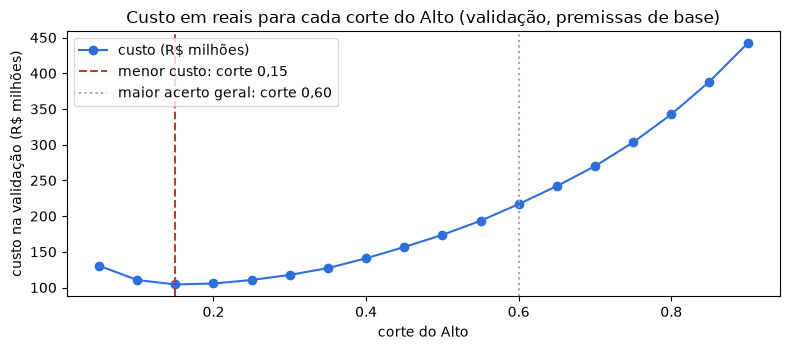

Corte pelo menor custo (escolhido na validação): 0,15
No teste, com esse corte: recall Alto 0,9128 | precisão Alto 0,1980 | F1 macro 0,4274
Custo no teste: R$ 215,5 milhões


In [14]:
y_va_np = y_va.values
cortes_teste = np.round(np.arange(0.05, 0.91, 0.05), 2)
curva = []
for corte_alto in cortes_teste:
    prev = pm.decidir(prob_va[escolhido], corte_alto, cortes[escolhido]['corte_medio'])
    total, avisos, perdidos = custo_total(y_va_np, prev)
    m = pm.metricas(y_va_np, prev)
    curva.append({'corte do Alto': corte_alto, 'custo (R$ milhões)': total / 1e6, 'recall Alto': m['recall_alto'],
                  'precisão Alto': m['precisao_alto']})
curva = pd.DataFrame(curva).set_index('corte do Alto')
corte_custo = curva['custo (R$ milhões)'].idxmin()

fig, eixo = plt.subplots(figsize=(8, 3.6))
curva['custo (R$ milhões)'].plot(ax=eixo, color=AZUL, marker='o')
eixo.axvline(corte_custo, color=VERMELHO, linestyle='--', label=f'menor custo: corte {corte_custo:.2f}'.replace('.', ','))
eixo.axvline(cortes[escolhido]['corte_alto'], color=CINZA, linestyle=':', label=f"maior acerto geral: corte {cortes[escolhido]['corte_alto']:.2f}".replace('.', ','))
eixo.set_ylabel('custo na validação (R$ milhões)')
eixo.set_title('Custo em reais para cada corte do Alto (validação, premissas de base)')
eixo.legend()
plt.tight_layout()
plt.show()

prev_custo = pm.decidir(prob_te[escolhido], corte_custo, cortes[escolhido]['corte_medio'])
no_teste = pm.metricas(y_te, prev_custo)
print(f'Corte pelo menor custo (escolhido na validação): {corte_custo:.2f}'.replace('.', ','))
print(f"No teste, com esse corte: recall Alto {no_teste['recall_alto']:.4f} | precisão Alto {no_teste['precisao_alto']:.4f} | F1 macro {no_teste['f1_macro']:.4f}".replace('.', ','))
print(f'Custo no teste: R$ {custo_total(y_te, prev_custo)[0] / 1e6:.1f} milhões'.replace('.', ','))
curva.round(4).to_csv(RELATORIOS / 'custo_por_corte_validacao.csv')
pd.DataFrame([{'corte_alto_custo': corte_custo, 'corte_alto_f1': cortes[escolhido]['corte_alto'],
               **no_teste, 'custo_teste_milhoes': round(custo_total(y_te, prev_custo)[0] / 1e6, 1)}]).round(4).to_csv(
    RELATORIOS / 'corte_pelo_custo_teste.csv', index=False)

**Pelo custo, o melhor corte é 0,15**, bem mais baixo que o do maior acerto geral (0,60). O motivo está nas
premissas: com 5 hectares a mais, um dia Alto sem aviso custa R$ 26.250, o mesmo que cerca de 25 diárias de
equipe. Com essa diferença, compensa avisar quase todo dia com algum sinal de risco. No teste, esse corte avisa
**91 de cada 100 dias Alto**, mas só 20 de cada 100 avisos são certos, a um custo de R$ 215,5 milhões (contra R$ 429,2
milhões com o corte do acerto geral).

Esse resultado depende muito da premissa dos hectares, a mais incerta. A tabela abaixo refaz a escolha do
corte, na validação, para cada cenário de área, e mede o resultado no teste.

In [15]:
por_cenario = []
for h in [1, 2, 5, 10, 20]:
    custos = {c: custo_total(y_va_np, pm.decidir(prob_va[escolhido], c, cortes[escolhido]['corte_medio']), hectares=h)[0]
              for c in cortes_teste}
    melhor_corte = min(custos, key=custos.get)
    m = pm.metricas(y_te, pm.decidir(prob_te[escolhido], melhor_corte, cortes[escolhido]['corte_medio']))
    por_cenario.append({'área a mais queimada sem equipe': f'{h} ha', 'corte de menor custo': melhor_corte,
                        'dias Alto avisados (de 100)': round(m['recall_alto'] * 100, 1),
                        'avisos certos (de 100)': round(m['precisao_alto'] * 100, 1)})
por_cenario = pd.DataFrame(por_cenario).set_index('área a mais queimada sem equipe')
por_cenario.to_csv(RELATORIOS / 'corte_por_cenario.csv')
por_cenario

,corte de menor custo,dias Alto avisados (de 100),avisos certos (de 100)
área a mais queimada sem equipe,,,
1 ha,0.45,65.3,44.6
2 ha,0.30,79.3,31.9
5 ha,0.15,91.3,19.8
10 ha,0.10,95.0,15.4
20 ha,0.05,98.3,10.3


**Quanto mais caro o incêndio sem equipe, mais baixo o corte e mais dias avisados.** Com 1 ha, o melhor corte é 0,45 e
avisa 65,3 de cada 100 dias Alto; com 20 ha, o corte cai para o mínimo testado (0,05) e avisa quase todos,
com poucos avisos certos. A meta de 60 de cada 100 dias Alto avisados é atingida em todos os cenários, até no
de 1 ha: o que separa os cenários é quantos avisos sem fogo cada um aceita.

Isso mostra a escolha que o gestor precisa fazer: avisar mais (mais equipes de prontidão sem fogo) ou avisar
menos (mais incêndios sem equipe). O modelo não decide isso sozinho; ele mostra o preço de cada opção, e o
corte certo depende de quanto custa, de fato, um incêndio sem resposta rápida em cada região.

## 8. Plano de teste A/B

O curso pede só o **plano**, não o teste. A ideia: comprovar, na prática, que posicionar equipes pelo modelo
reduz o dano dos incêndios em relação à forma atual.

| Elemento | No plano |
|---|---|
| **Hipótese** | Regiões que posicionam equipes pelo modelo têm menos área queimada por foco do que regiões que seguem a forma atual. |
| **H0 e H1** | H0 (a hipótese nula, que o teste tenta derrubar): a área queimada por foco é igual nos dois grupos. H1 (a alternativa): ela é menor no grupo B |
| **Controle (A)** | regiões que posicionam as equipes como hoje (previsão de risco de fogo do Instituto Nacional de Pesquisas Espaciais, o INPE, previsão do tempo e conhecimento local) |
| **Tratamento (B)** | regiões que usam, além disso, a lista diária de municípios em risco Alto do modelo |
| **Unidade sorteada** | **grupos de municípios vizinhos**, e não municípios soltos: o fogo atravessa fronteiras, e uma equipe do grupo B poderia ajudar um vizinho do grupo A (contaminação) |
| **Sorteio em pares** | antes do sorteio, grupos da mesma região com histórico parecido de fogo (mesmo bioma, o grande tipo de vegetação, e mesma faixa de focos em 2024) formam pares, e cada par tem um grupo em A e outro em B |
| **Métrica principal** | área queimada por foco detectado, medida por satélite |
| **Métricas secundárias** | tempo até a primeira resposta; focos que viraram incêndio grande (Alto no dia seguinte) |
| **Métricas de proteção** | custo de prontidão por grupo e número de dias Alto sem equipe: não podem piorar |
| **Duração** | uma estação seca inteira (agosto a outubro), quando há fogo suficiente para medir diferença |
| **Tamanho** | calculado antes do início, com α de 5% (o risco aceito de ver uma diferença que não existe) e poder de 80% (a chance de enxergar uma diferença que existe), a partir da variação da área queimada entre grupos em 2024 |
| **Nota de corte** | fixada antes do início e mantida até o fim do teste |
| **Decisão** | teste estatístico sobre a métrica principal ao fim da estação, sem olhar o resultado no meio para parar antes. O modelo é adotado se H0 for rejeitada e as métricas de proteção não piorarem |
| **Ética** | o grupo A não perde nada: continua com a estratégia atual. O modelo só se soma a ela no grupo B |

## 9. Conclusões

1. **Os três modelos superam a persistência** no acerto geral e no F1 do Alto, no período de teste (novembro a
   fevereiro), que é o mais difícil, por ser época de chuva. A **regressão logística** foi escolhida pela validação.
2. **Metas:** o acerto geral (0,5649) e os avisos certos no Alto (58,7 de cada 100) foram atingidos. Os dias Alto
   avisados (49,9 de cada 100, com o corte do maior acerto geral) ficaram abaixo da meta de 60. Pelo custo em reais, um
   corte mais baixo passa dessa meta, o que mostra que ela é uma escolha de custo, e não só de modelo.
3. **O resultado se sustenta em parte:** vale em municípios que o modelo nunca viu e em 3 de 5 meses, os de mais fogo.
   Em janeiro e fevereiro, ele fica abaixo da persistência.
4. **Limitação:** o ganho está nos municípios maiores (2 das 5 faixas de tamanho, com cerca de 80% dos dias Alto).
   Nos pequenos, a persistência ainda acerta mais.
5. **Em reais:** com premissas públicas (salários do Prevfogo e prejuízo por hectare da CNA), o modelo custa
   R$ 5,6 milhões a menos que a persistência no período de teste (1,3%), e a economia é positiva em
   15 dos 15 cenários.
6. **Para a Etapa 3:** otimizar o LightGBM com o Optuna, testar um corte por faixa de tamanho, explicar as decisões
   com o SHAP (um método que mostra quanto cada coluna pesou em cada previsão), testar o viés (o modelo errar mais para um grupo) por região e bioma
   e gerar o boletim em texto.

Os resultados também estão salvos em CSV na pasta `resultados/etapa2/`.